# 03 · Proposed: kiểm toán V1–V4, ablation một yếu tố, chọn bản cuối theo DEV

Proposed = PhoWhisper-small (giữ nguyên, không LoRA) → VinAI Translate vi2en-v2 + **LoRA** (khối dịch).
- **V1–V4** là các *phiên bản* nối tiếp (mỗi bản đổi một yếu tố so với bản trước) – giữ nguyên checkpoint/kết quả cũ, không train lại.
- **Ablation mới** (03/11/2026): so với **V2**, mỗi thí nghiệm đổi **đúng một** yếu tố: rank LoRA 8, rank LoRA 32, augmentation dữ liệu dịch.
- **Quy tắc chọn bản** chốt trước khi chạy ablation: `reports/ablation/QUY_TAC_CHON.md`. Chỉ dùng số DEV, nhưng quy tắc chốt sau khi đã có số test của V1–V4 (quy tắc đầu cho ra V3), nên không phải lựa chọn mù với test.

Mỗi lần train ~35 phút + chấm 5 tập ~17 phút (RTX 4060). Checkpoint mỗi epoch ở `checkpoints/<bản>/epoch_k` (adapter + optimizer + RNG, resume được),
bản chọn ở `checkpoints/<bản>/best`. Chạy lại notebook sẽ bỏ qua phần đã xong.

In [1]:
import os, sys, json, csv, subprocess, time, shutil, statistics, re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Thư mục thực nghiệm (có scripts/, data/, checkpoints/): task3/ – notebook nằm ở task3/notebooks/
T3 = next(c for c in [Path.cwd().parent, Path.cwd(), Path(r"D:\CAIDCM\teamwork\task3")] if (c / "scripts" / "mt" / "train_lora.py").exists())
os.chdir(T3); TW = T3.parent
PY = sys.executable
ENV = dict(os.environ, HF_HUB_CACHE=str(T3 / "hf_home" / "hub"), HF_HUB_OFFLINE="1", HF_HUB_DISABLE_TELEMETRY="1",
           PYTHONIOENCODING="utf-8", PYTHONUTF8="1")
MTREV = "ae7baa85da07dbe8e23ac26a9f5ef560c17e2138"
BO_QUA = ("Warning", "warnings.warn", "warn(", "forced_decoder_ids", "attention mask", "fget.__get__", "TypedStorage")

def chay(*lenh, log=None):
    """Chạy 1 script của project (cùng venv), in log từng dòng, ghi thêm vào file log nếu có; lỗi thì dừng ô."""
    t0 = time.time()
    p = subprocess.Popen([PY, "-X", "utf8", *map(str, lenh)], cwd=T3, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, encoding="utf-8", errors="replace")
    fl = open(T3 / log, "a", encoding="utf-8") if log else None
    for d in p.stdout:
        if fl: fl.write(d)
        if not any(x in d for x in BO_QUA): print(d, end="")
    p.wait(); fl and fl.close()
    print(f"--- mã thoát {p.returncode} · {time.time() - t0:.0f} s")
    if p.returncode: raise RuntimeError(f"lệnh lỗi: {lenh}")

J = lambda p: json.loads(Path(p).read_text(encoding="utf-8"))
def mt(v, s):
    p = T3 / "runs/mt" / v / s / "score.json"
    return J(p) if p.exists() else None
vn = lambda x, d=2: "–" if x is None else f"{float(x):.{d}f}".replace(".", ",")
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
import torch
print("Thư mục:", T3, "| Python", sys.version.split()[0], "| torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG")

Thư mục: D:\CAIDCM\teamwork\task3 | Python 3.11.1 | torch 2.0.1+cu117 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Kiểm toán V1–V4 (đọc config, nhật ký epoch, checkpoint thật)

In [2]:
rows = []
for v in ("V1", "V2", "V3", "V4"):
    c, e, ch_ = J(f"checkpoints/{v}/config.json"), J(f"checkpoints/{v}/epochs.json"), J(f"checkpoints/{v}/best/chon.json")
    ep = sorted(p.name for p in (T3 / "checkpoints" / v).glob("epoch_*"))
    rows.append({"bản": v, "dữ liệu train": " + ".join(Path(x).stem for x in c["train"]), "n_train": c["n_train"], "lr": c["lr"],
                 "rank/alpha": f"{c['lora_r']}/{c['lora_alpha']}", "lớp đích": c["targets"], "batch×accum": f"{c['batch_size']}×{c['grad_accum']}",
                 "epochs": c["epochs"], "seed": c["seed"], "tham số train": c["trainable_params"], "checkpoint": ", ".join(ep),
                 "epoch chọn": ch_["best_epoch"], "dev BLEU (chọn)": ch_["dev_BLEU_translate"]})
display(pd.DataFrame(rows))
print("Rò rỉ: sent_id train ∩ dev/test =", len({json.loads(l)["sent_id"] for l in open("runs/mt_data/fleurs_train_asr_pho.jsonl", encoding="utf-8")}
      & {json.loads(l)["sent_id"] for f in ("fleurs_dev_asr_pho", "fleurs_test_asr_pho") for l in open(f"runs/mt_data/{f}.jsonl", encoding="utf-8")}))

,bản,dữ liệu train,n_train,lr,rank/alpha,lớp đích,batch×accum,epochs,seed,tham số train,checkpoint,epoch chọn,dev BLEU (chọn)
0,V1,fleurs_train_asr_pho,2926,0.00020,16/32,"q_proj,k_proj,v_proj,out_proj,fc1,fc2",4×4,5,42,8650752,"epoch_1, epoch_2, epoch_3, epoch_4, epoch_5",1,26.47
1,V2,fleurs_train_asr_pho + phomt_train_mix,7394,0.00020,16/32,"q_proj,k_proj,v_proj,out_proj,fc1,fc2",4×4,5,42,8650752,"epoch_1, epoch_2, epoch_3, epoch_4, epoch_5",1,26.45
2,V3,fleurs_train_asr_pho_canbang + phomt_train_mix,8936,0.00020,16/32,"q_proj,k_proj,v_proj,out_proj,fc1,fc2",4×4,5,42,8650752,"epoch_1, epoch_2, epoch_3, epoch_4, epoch_5",1,26.71
3,V4,fleurs_train_asr_pho_canbang + phomt_train_mix,8936,0.00005,16/32,"q_proj,k_proj,v_proj,out_proj,fc1,fc2",4×4,5,42,8650752,"epoch_1, epoch_2, epoch_3, epoch_4, epoch_5",1,26.33


Rò rỉ: sent_id train ∩ dev/test = 0


## 2. Quy tắc chọn bản (đã ghi file trước khi chạy ablation)

In [3]:
display(Markdown((T3 / "reports/ablation/QUY_TAC_CHON.md").read_text(encoding="utf-8")))
print("Ghi lúc:", time.strftime("%d/%m/%Y %H:%M", time.localtime((T3 / "reports/ablation/QUY_TAC_CHON.md").stat().st_mtime)))

# Quy tắc chọn bản cuối (chốt TRƯỚC khi chạy ablation mới) – 03/11/2026 23:38

Áp cho mọi bản khối dịch: V1, V2, V3, V4 và các bản ablation A_r8, A_r32, A_aug. Chỉ dùng tập **DEV** (FLEURS dev, 361 bản thu); test chỉ xem sau khi đã chọn.

1. Tính BLEU dev cascade (dịch lời PhoWhisper của FLEURS dev, `runs/mt/<bản>/fleurs_dev_asr_pho/score.json`). Gọi M = giá trị cao nhất.
2. Nhóm "hoà": mọi bản có BLEU dev cascade ≥ M − 0,5 (0,5 BLEU ≈ mức chênh mà bootstrap trên test không phân biệt được giữa V1–V4).
3. Trong nhóm hoà, chọn bản có **BLEU dev dịch sạch** cao nhất (`fleurs_dev_clean`) – tiêu chí Task 1 "không làm giảm chất lượng dịch văn bản chuẩn".
4. Nếu vẫn bằng nhau (chênh < 0,01): chọn bản ít tham số huấn luyện hơn, rồi bản có tên đứng trước.

Ablation (chỉ đổi 1 yếu tố so với **V2**, bản đang thắng theo quy tắc này với V1–V4):
- A_r8: LoRA rank 8 (alpha = 2·rank = 16, giữ tỉ lệ alpha/rank như V2)
- A_r32: LoRA rank 32 (alpha = 64)
- A_aug: dữ liệu V2 + 2.926 cặp transcript SẠCH FLEURS train đổi sang dạng lời ASR (chữ thường, bỏ dấu câu) – chỉ dùng TRAIN, không chạm dev/test
Mọi thứ khác giữ như V2: lr 2e-4, batch 4×4, 5 epoch, warmup 6%, dropout 0,05, 6 lớp đích, seed 42, chọn epoch theo BLEU dev cascade.


Ghi lúc: 03/11/2026 23:38


**Ghi chú khi đọc quy tắc trên.** File quy tắc được giữ nguyên như đã ghi ngày 03/11. Câu "test chỉ xem sau khi đã chọn" chỉ áp cho ba bản ablation, là các bản chạy sau khi có quy tắc. Với V1–V4, nhóm đã có số test trước khi viết quy tắc này; quy tắc đầu lấy dev cascade cao nhất và cho ra V3. Vì vậy đây không phải lựa chọn mù với test.

## 3. Dữ liệu augmentation (chỉ từ TRAIN) – `scripts/mt/make_aug_data.py`

In [4]:
chay("scripts/mt/make_aug_data.py")
aug = pd.read_json("runs/mt_data/fleurs_train_clean_asrstyle.jsonl", lines=True); goc = pd.read_json("runs/mt_data/fleurs_train_asr_pho.jsonl", lines=True)
display(pd.DataFrame({"lời ASR (đã có trong V2)": goc.src.head(3).values, "transcript sạch → dạng ASR (thêm vào A_aug)": aug.src.head(3).values, "câu Anh (giữ nguyên)": aug.ref.head(3).values}))

D:\CAIDCM\teamwork\task3\runs\mt_data\fleurs_train_clean_asrstyle.jsonl | 2926 cặp | 0 câu trùng dev/test | ví dụ: Ở thành phố Harappa và Mohenjo-daro, hầu như nhà nào cũng có cầu tiêu xối nước nối vào một hệ thống cống rãnh phức tạp. → ở thành phố harappa và mohenjo daro hầu như nhà nào cũng có cầu tiêu xối nước nối vào một hệ thống cống rãnh phức tạp.
--- mã thoát 0 · 0 s


,lời ASR (đã có trong V2),transcript sạch → dạng ASR (thêm vào A_aug),câu Anh (giữ nguyên)
0,ở thành phố harápba và mohamed radaror hầu như nhà nào cũng có cầu tiêu xói nước nối và một hệ thống cống ...,ở thành phố harappa và mohenjo daro hầu như nhà nào cũng có cầu tiêu xối nước nối vào một hệ thống cống rã...,"The cities of Harappa and Mohenjo-daro had a flush toilet in almost every house, attached to a sophisticat..."
1,hai phần ba số người venezuela đi làm làm việc trong ngành dịch vụ gần một phần tư làm việc trong ngành cô...,hai phần ba số người venezuela đi làm làm việc trong ngành dịch vụ gần một phần tư làm việc trong ngành cô...,"Two thirds of Venezuelans who work do so in the service sector, nearly a quarter work in industry and a fi..."
2,mỗi chương trình cũng sẽ đưa ra đề xuất về những cuốn sách mà trẻ em nên tìm đọc khi đến thư viện.,mỗi chương trình cũng sẽ đưa ra đề xuất về những cuốn sách mà trẻ em nên tìm đọc khi đến thư viện.,Each show would also provide recommendations for books that children should look for when they went to the...


## 4. Cấu hình ablation (chỉ khác V2 đúng một yếu tố)

In [5]:
V2c = J("checkpoints/V2/config.json")
CHUNG = ["--dev", "runs/mt_data/fleurs_dev_asr_pho.jsonl", "--revision", MTREV, "--epochs", V2c["epochs"], "--lr", V2c["lr"],
         "--batch_size", V2c["batch_size"], "--grad_accum", V2c["grad_accum"], "--warmup_ratio", V2c["warmup_ratio"], "--lora_dropout", V2c["lora_dropout"],
         "--targets", V2c["targets"], "--max_len", V2c["max_len"], "--seed", V2c["seed"], "--resume"]
TRAIN_V2 = ["runs/mt_data/fleurs_train_asr_pho.jsonl", "runs/mt_data/phomt_train_mix.jsonl"]
AB = {"A_r8":  {"doi": "LoRA rank 16 → 8 (alpha 32 → 16, giữ alpha/rank = 2)", "train": TRAIN_V2, "r": 8, "alpha": 16},
      "A_r32": {"doi": "LoRA rank 16 → 32 (alpha 32 → 64)", "train": TRAIN_V2, "r": 32, "alpha": 64},
      "A_aug": {"doi": "+ 2.926 cặp transcript sạch FLEURS train dạng ASR (augmentation)", "train": TRAIN_V2 + ["runs/mt_data/fleurs_train_clean_asrstyle.jsonl"], "r": 16, "alpha": 32}}
for k, a in AB.items():
    (T3 / "configs/mt").mkdir(exist_ok=True)
    (T3 / f"configs/mt/{k}.json").write_text(json.dumps({"version": k, "base": "V2", "change_vs_V2": a["doi"], "train": a["train"], "lora_r": a["r"], "lora_alpha": a["alpha"],
        **{x: V2c[x] for x in ("epochs", "lr", "batch_size", "grad_accum", "warmup_ratio", "lora_dropout", "targets", "max_len", "seed")},
        "selection": "epoch: BLEU dev cascade qua translate.py; bản cuối: reports/ablation/QUY_TAC_CHON.md"}, ensure_ascii=False, indent=1), encoding="utf-8")
display(pd.DataFrame([{"bản": k, "thay đổi so với V2": a["doi"], "rank/alpha": f"{a['r']}/{a['alpha']}", "file train": " + ".join(Path(x).stem for x in a["train"])} for k, a in AB.items()]))

,bản,thay đổi so với V2,rank/alpha,file train
0,A_r8,"LoRA rank 16 → 8 (alpha 32 → 16, giữ alpha/rank = 2)",8/16,fleurs_train_asr_pho + phomt_train_mix
1,A_r32,LoRA rank 16 → 32 (alpha 32 → 64),32/64,fleurs_train_asr_pho + phomt_train_mix
2,A_aug,+ 2.926 cặp transcript sạch FLEURS train dạng ASR (augmentation),16/32,fleurs_train_asr_pho + phomt_train_mix + fleurs_train_clean_asrstyle


## 5. Huấn luyện (checkpoint mỗi epoch; có `best/` thì bỏ qua)

A_r8 đã train xong – nạp kết quả: 1 epoch chọn


,epoch,dev_loss,dev_BLEU_translate,dev_chrF++_translate,minutes
0,1,1.388880,25.97,52.58,12.82
1,2,1.430358,25.55,52.30,15.00
2,3,1.516113,25.56,52.00,9.61
3,4,1.615341,24.82,51.36,8.04
4,5,1.686605,24.43,51.19,8.19


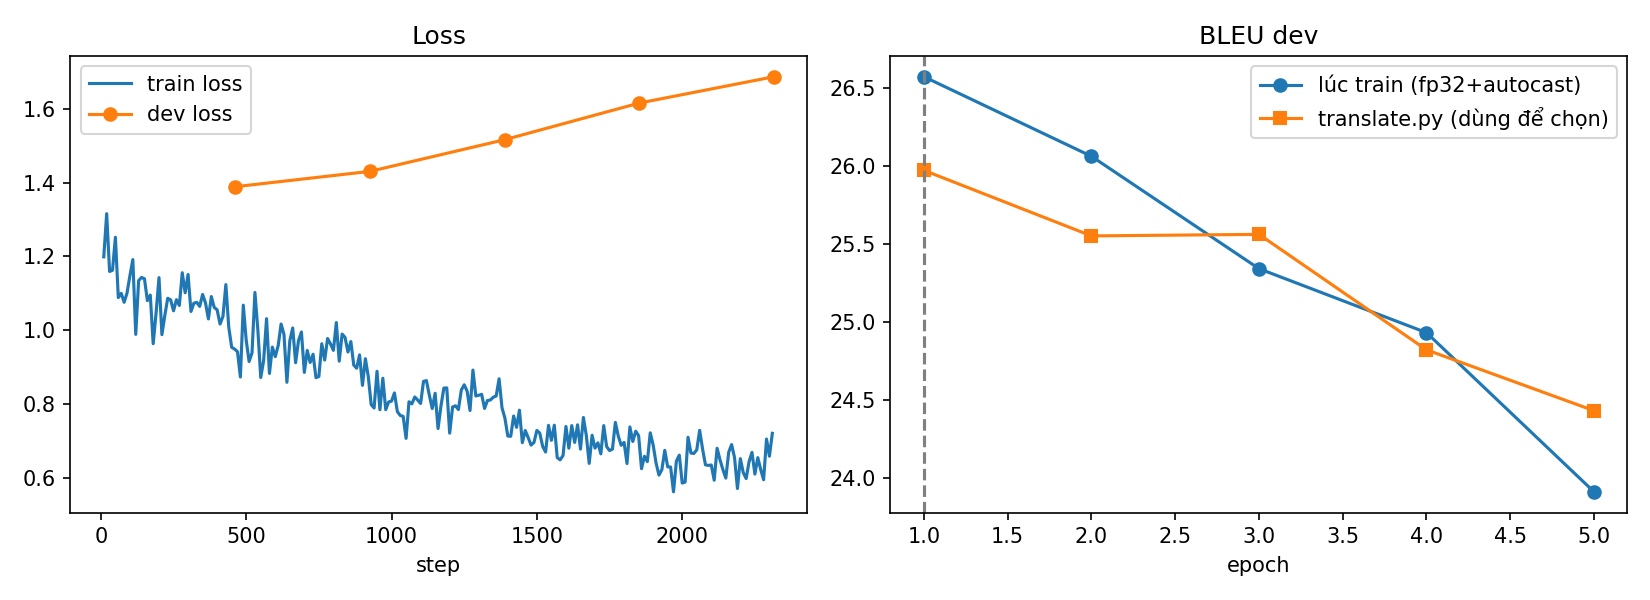

In [6]:
k = "A_r8"
if (T3 / "checkpoints" / k / "best" / "chon.json").exists():
    print(k, "đã train xong – nạp kết quả:", J(f"checkpoints/{k}/best/chon.json")["best_epoch"], "epoch chọn")
else:
    chay("scripts/mt/train_lora.py", "--train", *AB[k]["train"], "--out_dir", f"checkpoints/{k}", "--lora_r", AB[k]["r"], "--lora_alpha", AB[k]["alpha"], *CHUNG, log=f"logs/train_{k}.log")
display(pd.DataFrame(J(f"checkpoints/{k}/epochs.json"))[["epoch", "dev_loss", "dev_BLEU_translate", "dev_chrF++_translate", "minutes"]])
display(Image(filename=str(T3 / "checkpoints" / k / "curves.png"), width=760))

A_r32 đã train xong – nạp kết quả: 1 epoch chọn


,epoch,dev_loss,dev_BLEU_translate,dev_chrF++_translate,minutes
0,1,1.400433,25.88,52.81,6.81
1,2,1.534832,25.43,52.00,6.78
2,3,1.757866,24.38,50.85,7.01
3,4,2.099109,23.26,49.77,7.48
4,5,2.304312,22.27,48.66,7.42


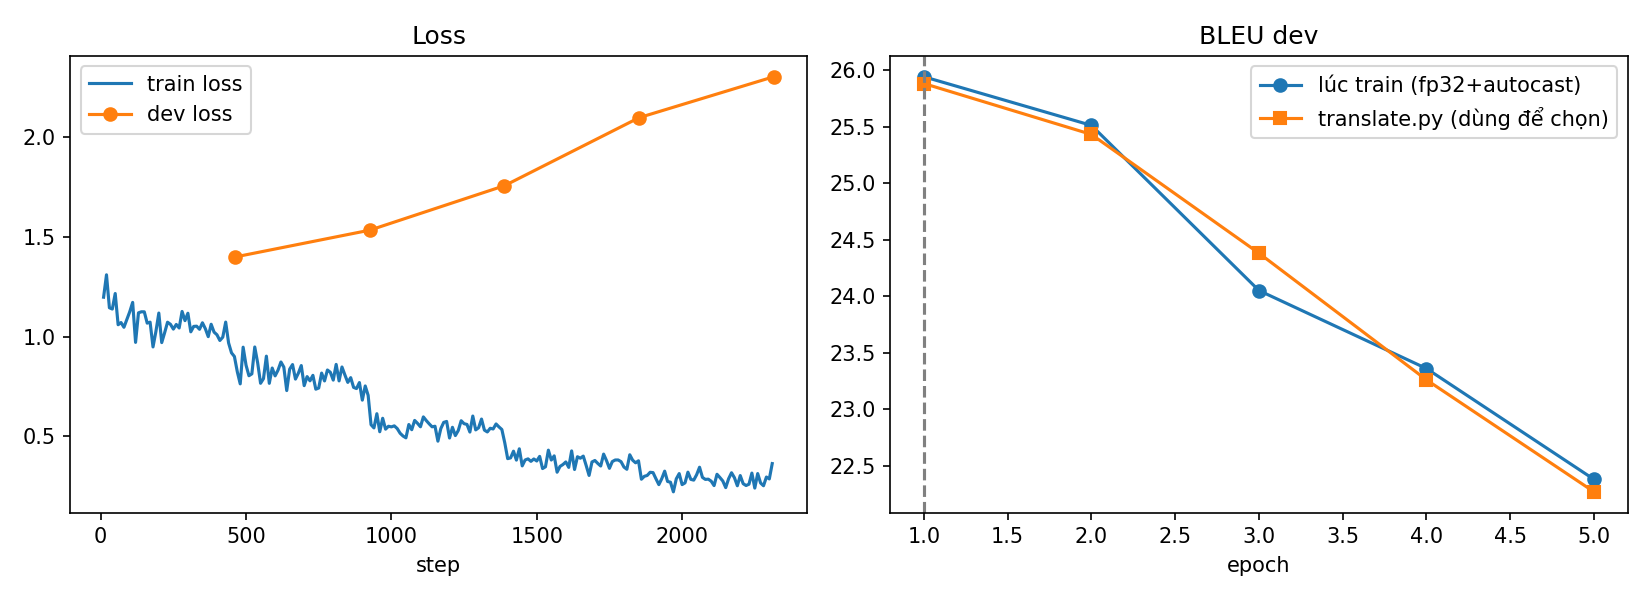

In [7]:
k = "A_r32"
if (T3 / "checkpoints" / k / "best" / "chon.json").exists():
    print(k, "đã train xong – nạp kết quả:", J(f"checkpoints/{k}/best/chon.json")["best_epoch"], "epoch chọn")
else:
    chay("scripts/mt/train_lora.py", "--train", *AB[k]["train"], "--out_dir", f"checkpoints/{k}", "--lora_r", AB[k]["r"], "--lora_alpha", AB[k]["alpha"], *CHUNG, log=f"logs/train_{k}.log")
display(pd.DataFrame(J(f"checkpoints/{k}/epochs.json"))[["epoch", "dev_loss", "dev_BLEU_translate", "dev_chrF++_translate", "minutes"]])
display(Image(filename=str(T3 / "checkpoints" / k / "curves.png"), width=760))

A_aug đã train xong – nạp kết quả: 1 epoch chọn


,epoch,dev_loss,dev_BLEU_translate,dev_chrF++_translate,minutes
0,1,1.463742,24.60,51.96,8.84
1,2,1.781137,22.39,50.12,9.20
2,3,2.172036,21.97,48.71,9.49
3,4,2.506088,21.11,48.45,10.50
4,5,2.642869,20.64,48.20,10.22


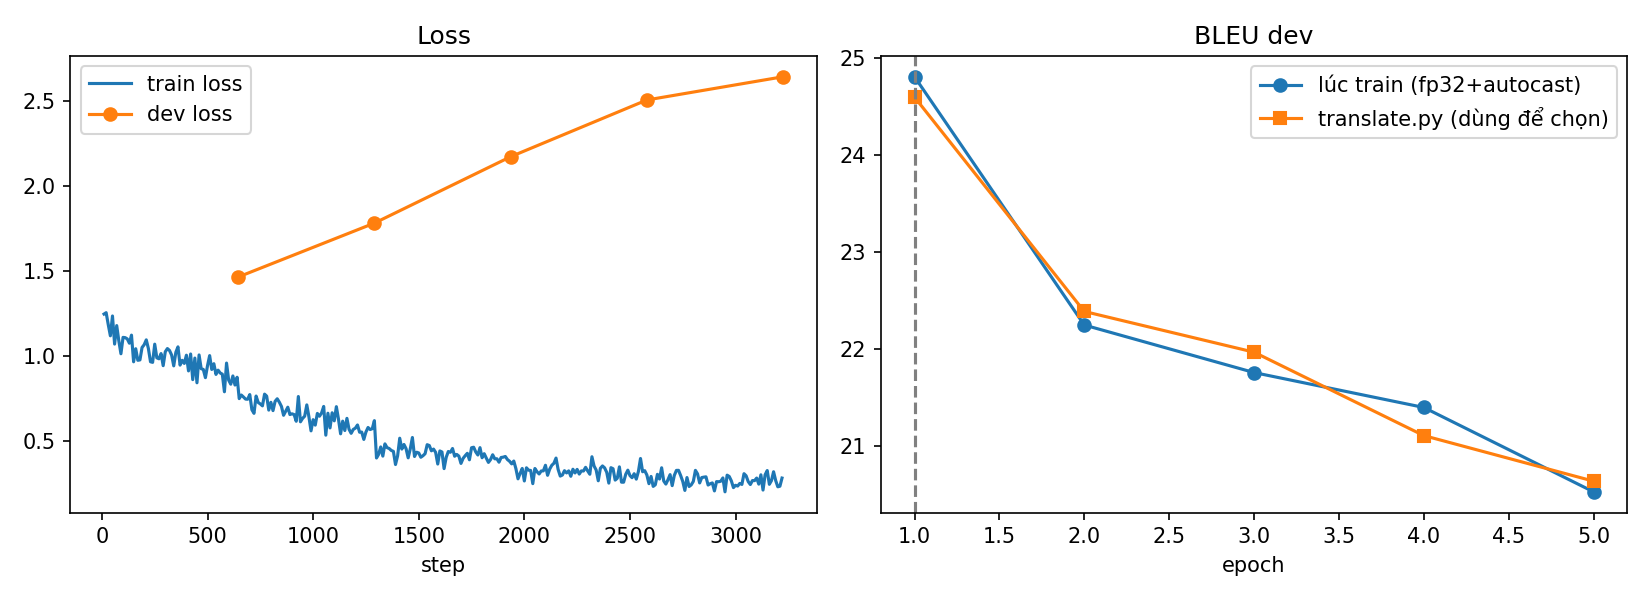

In [8]:
k = "A_aug"
if (T3 / "checkpoints" / k / "best" / "chon.json").exists():
    print(k, "đã train xong – nạp kết quả:", J(f"checkpoints/{k}/best/chon.json")["best_epoch"], "epoch chọn")
else:
    chay("scripts/mt/train_lora.py", "--train", *AB[k]["train"], "--out_dir", f"checkpoints/{k}", "--lora_r", AB[k]["r"], "--lora_alpha", AB[k]["alpha"], *CHUNG, log=f"logs/train_{k}.log")
display(pd.DataFrame(J(f"checkpoints/{k}/epochs.json"))[["epoch", "dev_loss", "dev_BLEU_translate", "dev_chrF++_translate", "minutes"]])
display(Image(filename=str(T3 / "checkpoints" / k / "curves.png"), width=760))

## 6. Chấm 5 tập như V1–V4 (dev cascade, dev sạch, test cascade, test sạch, PhoMT test) – `scripts/mt/translate.py`

In [9]:
TAP = ["fleurs_dev_asr_pho", "fleurs_dev_clean", "fleurs_test_asr_pho", "fleurs_test_clean", "phomt_test"]
for k in AB:
    for s in TAP:
        if mt(k, s) is None:
            chay("scripts/mt/translate.py", "--input", f"runs/mt_data/{s}.jsonl", "--out_dir", f"runs/mt/{k}/{s}", "--revision", MTREV,
                 "--adapter", f"checkpoints/{k}/best", log=f"logs/eval_{k}.log")
print("đủ điểm:", {k: all(mt(k, s) for s in TAP) for k in AB})

đủ điểm:

 {'A_r8': True, 'A_r32': True, 'A_aug': True}


## 7. Áp quy tắc chọn trên DEV

In [10]:
BAN = ["V1", "V2", "V3", "V4", *AB]
dv = pd.DataFrame([{"bản": v, "dev cascade": mt(v, "fleurs_dev_asr_pho")["BLEU"], "dev sạch": mt(v, "fleurs_dev_clean")["BLEU"],
                    "tham số train": J(f"checkpoints/{v}/config.json")["trainable_params"]} for v in BAN])
M = dv["dev cascade"].max(); dv["hoà (≥ M−0,5)"] = dv["dev cascade"] >= M - 0.5
ung = dv[dv["hoà (≥ M−0,5)"]].sort_values(["dev sạch", "tham số train", "bản"], ascending=[False, True, True])
CHON = ung.iloc[0]["bản"]
display(dv)
print(f"M = {M} ({dv.loc[dv['dev cascade'].idxmax(), 'bản']}) · nhóm hoà: {list(ung['bản'])} · CHỌN theo dev sạch: {CHON}")
(T3 / "reports/ablation/chon_ban_cuoi.json").write_text(json.dumps({"quy_tac": "reports/ablation/QUY_TAC_CHON.md", "M_dev_cascade": M,
    "nhom_hoa": list(ung["bản"]), "ban_chon": CHON, "bang_dev": dv.to_dict("records"), "luc": time.strftime("%d/%m/%Y %H:%M")}, ensure_ascii=False, indent=1), encoding="utf-8")

,bản,dev cascade,dev sạch,tham số train,"hoà (≥ M−0,5)"
0,V1,26.47,35.97,8650752,True
1,V2,26.45,36.93,8650752,True
2,V3,26.71,36.37,8650752,True
3,V4,26.33,36.75,8650752,True
4,A_r8,25.97,36.74,4325376,False
5,A_r32,25.88,36.44,17301504,False
6,A_aug,24.60,37.30,8650752,False


M = 26.71 (V3) · nhóm hoà: ['V2', 'V4', 'V3', 'V1'] · CHỌN theo dev sạch: V2


1082

## 8. Bảng ablation trên test

,bản,dev cascade,dev sạch,test cascade,test sạch,PhoMT test,chrF++ test cascade,Δ test cascade so với V2 (KTC 95%)
0,"B0 (VinAI gốc, không LoRA)",22.96,37.57,22.69,38.27,40.79,49.38,NaN
1,V1 = B0 + LoRA (lời ASR),26.47,35.97,27.49,36.21,36.96,52.50,NaN
2,V2 = V1 + PhoMT 1:1,26.45,36.93,27.47,38.09,40.41,52.98,NaN
3,V3 = V2 + cân bằng câu/độ dài,26.71,36.37,27.33,36.76,39.58,52.25,NaN
4,V4 = V3 với lr 5e-5,26.33,36.75,27.37,38.11,40.08,52.51,NaN
5,A_r8 = V2 với rank 8,25.97,36.74,27.26,37.96,40.47,52.82,"-0.21 [-0.91; 0.33], p = 0.738"
6,A_r32 = V2 với rank 32,25.88,36.44,27.62,37.96,40.27,52.93,"+0.15 [-0.28; 0.56], p = 0.268"
7,A_aug = V2 + augmentation,24.60,37.30,25.49,36.65,39.57,51.61,"-1.99 [-2.87; -1.21], p = 1.0"


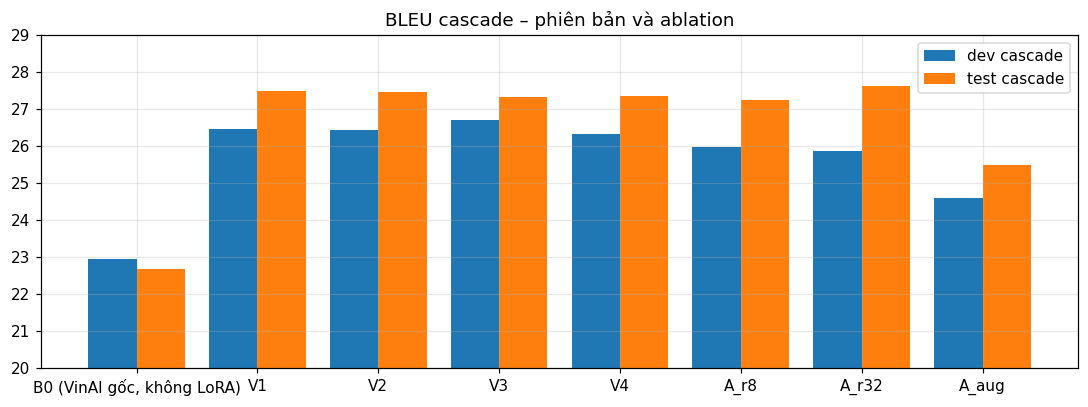

Bản chọn theo DEV: V2


In [11]:
TEN = {"B0": "B0 (VinAI gốc, không LoRA)", "V1": "V1 = B0 + LoRA (lời ASR)", "V2": "V2 = V1 + PhoMT 1:1", "V3": "V3 = V2 + cân bằng câu/độ dài",
       "V4": "V4 = V3 với lr 5e-5", "A_r8": "A_r8 = V2 với rank 8", "A_r32": "A_r32 = V2 với rank 32", "A_aug": "A_aug = V2 + augmentation"}
rows = []
for v in ["B0", *BAN]:
    r = {"bản": TEN[v]} | {s: mt(v, s)["BLEU"] for s in TAP} | {"chrF++ test cascade": mt(v, "fleurs_test_asr_pho")["chrF++"]}
    bs = T3 / f"reports/mt/bootstrap_V2_{v}_cascade_test.json"
    if v.startswith("A_"):
        if not bs.exists():
            chay("scripts/mt/bootstrap.py", "--a", "runs/mt/V2/fleurs_test_asr_pho/hyp.jsonl", "--b", f"runs/mt/{v}/fleurs_test_asr_pho/hyp.jsonl",
                 "--data", "runs/mt_data/fleurs_test_asr_pho.jsonl", "--out", bs, "--n", 1000)
        b = J(bs); r["Δ test cascade so với V2 (KTC 95%)"] = f"{b['delta']:+.2f} [{b['ci95'][0]}; {b['ci95'][1]}], p = {b['p_one_sided_delta_le_0']}"
    rows.append(r)
ab = pd.DataFrame(rows).rename(columns={"fleurs_dev_asr_pho": "dev cascade", "fleurs_dev_clean": "dev sạch", "fleurs_test_asr_pho": "test cascade",
                                        "fleurs_test_clean": "test sạch", "phomt_test": "PhoMT test"})
display(ab); ab.to_csv(T3 / "reports/ablation/bang_ablation.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(10, 3.8)); x = range(len(ab))
ax.bar([i - .2 for i in x], ab["dev cascade"], .4, label="dev cascade"); ax.bar([i + .2 for i in x], ab["test cascade"], .4, label="test cascade")
ax.set_xticks(list(x)); ax.set_xticklabels([t.split(" =")[0] for t in ab["bản"]]); ax.set_ylim(20, 29); ax.legend(); ax.set_title("BLEU cascade – phiên bản và ablation")
plt.tight_layout(); plt.savefig(T3 / "reports/ablation/bang_ablation.png", dpi=130); plt.show()
print("Bản chọn theo DEV:", J("reports/ablation/chon_ban_cuoi.json")["ban_chon"])

## 9. Kết luận: vì sao chọn V2

**Bản cuối là V2 (seed 42).** Lý do theo từng bước của quy tắc DEV, số lấy từ ô mục 7:

1. Dev cascade cao nhất là M = 26,71 (V3), nên ngưỡng hoà là 26,21.
2. V1 (26,47), V2 (26,45), V3 (26,71), V4 (26,33) nằm trong nhóm hoà. A_r8 (25,97), A_r32 (25,88), A_aug (24,60) bị loại.
3. Trong nhóm hoà, dev sạch của V2 cao nhất: V2 36,93, V4 36,75, V3 36,37, V1 35,97.

**Vì sao V2 thắng V3 dù V3 có dev cascade cao nhất:** chênh lệch 0,26 BLEU nằm trong ngưỡng hoà, còn dev sạch của V2 cao hơn V3 0,56 BLEU. Quy tắc ưu tiên bản ít làm giảm chất lượng dịch văn bản chuẩn, là tiêu chí của Task 1.

**Vì sao không chọn A_r32 dù test cascade 27,62 cao hơn V2 27,47:** A_r32 bị loại ngay từ DEV và không dùng test để chọn. Chênh lệch +0,15 cũng có khoảng tin cậy 95% [−0,28; 0,56] chứa 0.

**Kiểm tra độ nhạy trên 3 seed** (`04_kiem_tra_3_seed.ipynb`, V1–V4): áp lại quy tắc trên trung bình cho M = 26,64, nhóm hoà V1 và V2, dev sạch V2 36,75 so với V1 36,11, vẫn ra V2.

**Giới hạn cần nói rõ:**
- Quy tắc chốt sau khi đã có số test của V1–V4, nên không phải lựa chọn mù với test.
- V2 vẫn dịch văn bản sạch kém B0: dev sạch 36,93 so với 37,57; test sạch 38,09 so với 38,27. Trên 3 seed, test sạch là 37,80 ± 0,26, thấp hơn B0 0,47, và 0/3 seed đạt mức của B0.
